# A vida do SBSJ contada pelo ledger

Este notebook é o experimento do TG. Ele conta, em ordem, a história da pista do aeroporto de São José dos Campos (SBSJ) como o modelo a registraria: primeiro como o AIXM faria, só com formas; depois como premissas num ledger em que só se escreve; e então ao longo de obras, restrições, uma nova medição, uma auditoria e uma tentativa de adulteração.

Cada ato termina numa **célula de verificação**. Ela compara o que o modelo produziu com a predição do **protocolo de falseamento** (`protocolo/protocolo.yaml`), congelado antes de qualquer execução. Nenhuma tolerância é escolhida aqui: todas vêm do protocolo.

**Como ler os vereditos.** ✔ quer dizer que o observado ficou dentro da tolerância registrada; ✘, que não ficou. Uma falha só refuta a tese se a correção exigir violar um princípio da arquitetura; caso contrário, é falha de implementação, registrada e corrigida numa nova execução.

**Registro.** Cada execução ganha um identificador, um banco de dados próprio (que não é apagado) e linhas em `resultados/execucoes.jsonl`, arquivo em que só se acrescenta. Falhas de execuções anteriores continuam lá.

> Dados do AIP Brasil (DECEA) usados para pesquisa. O ADC gerado aqui reproduz o conteúdo da carta, não a cartografia do Anexo 4, e não substitui a publicação oficial.

In [1]:
import json, os, subprocess, sys
from datetime import datetime, timezone
from pathlib import Path

RAIZ = Path.cwd().resolve()
if RAIZ.name == "experimento":
    RAIZ = RAIZ.parent
for p in ("artefato", "experimento", "protocolo/gabarito"):
    sys.path.insert(0, str(RAIZ / p))

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from tg import adc as lente, derivacoes, ledger, motor, referencial, relogio
from tg.referencial import Resolvedor
import apoio, ataques, digitalizacao as dig, figuras, fontes as F, metricas
import geodesia as gab                     # gabarito independente, do protocolo
from registro import Registro

UTC = timezone.utc
s = apoio.seed

## Passo 0 — Preparação

Antes de contar a história, três conferências:

1. **O protocolo é o congelado.** O hash do `protocolo.yaml` em disco tem de ser igual ao do commit de congelamento (`fcfb6a5`) e ao registrado em `PROTOCOLO.sha256`. Se não for, o notebook para aqui.
2. **O artefato passa nos testes de verificação** (campo ausente, snapshot, ciclo de vida, regras do referencial, rejeições). São testes do mecanismo, sobre um aeródromo fictício; não falseiam nada.
3. **A execução tem um banco só dela**, criado vazio, com o esquema do artefato.

In [2]:
reg = Registro()
c = reg.congelamento
display(Markdown(f'''
- execução: `{reg.exec_id}` (commit do artefato `{reg.commit}`{"" if reg.commit_limpo else ", com alterações não commitadas"})
- protocolo em disco: `{c["sha256_disco"][:16]}…` · no commit de congelamento: `{c["sha256_commit"][:16]}…` · registrado: `{c["sha256_registrado"][:16]}…`
- íntegro: **{c["integro"]}** · tag: {c["tag"] or "ainda não criada (a âncora é o commit `fcfb6a5`)"}
'''))


- execução: `20261020T234807Z-ebc7ee7` (commit do artefato `ebc7ee7`)
- protocolo em disco: `dd453c3404ccda58…` · no commit de congelamento: `dd453c3404ccda58…` · registrado: `dd453c3404ccda58…`
- íntegro: **True** · tag: protocolo-v0.4


In [3]:
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider", str(RAIZ / "artefato" / "tests")],
                   capture_output=True, text=True)
reg.roteiro("P0", r.returncode == 0, "os testes de verificação do artefato passam",
            observado=r.stdout.strip().splitlines()[-1])

✔ P0: observado 39 passed in 3.57s | predito os testes de verificação do artefato passam → PASSOU


True

In [4]:
conn, BANCO = apoio.banco_da_execucao(reg.exec_id)
SAIDA = RAIZ / "resultados" / reg.exec_id
SAIDA.mkdir(parents=True, exist_ok=True)
reg.nota("banco da execução", banco=BANCO)
print("banco desta execução:", BANCO)

banco desta execução: tg_exp_20261020t234807z_ebc7ee7


## Prólogo — O problema

Primeiro, a pista registrada **em modo forma**, como o AIXM faria: cada número publicado vira um campo armazenado. Um BASELINE com os valores da AOC (AIRAC 2213, dezembro de 2022) e um DELTA com os do ADC (AIRAC 2604, abril de 2026), ambos afirmados pelo DECEA, com a edição como fonte.

Este registro fica num run à parte (`aixm`): é o sistema que o TG critica, não o modelo proposto.

In [5]:
RUN_F = relogio.novo_run(conn, F.AIRAC_2213, "aixm")
e2213, _ = reg.escrever(conn, RUN_F, "SBSJ-RWY-AIXM", "runway_forma", "BASELINE", corpo=F.FORMA_AIRAC_2213,
                        asserted_by="DECEA", reason="AOC AIRAC AMDT 2213A1")
apoio.avancar_ate(conn, RUN_F, F.AIRAC_2604)
antes, depois = ledger.achatar(F.FORMA_AIRAC_2213), ledger.achatar(F.FORMA_AIRAC_2604)
e2604, _ = reg.escrever(conn, RUN_F, "SBSJ-RWY-AIXM", "runway_forma", "DELTA",
                        alteracoes={p: v for p, v in depois.items() if antes[p] != v},
                        asserted_by="DECEA", reason="ADC AIRAC AMDT 2604A1")
D = ledger.diff(conn, RUN_F, e2213, e2604)
display(Markdown("| campo | AIRAC 2213 | AIRAC 2604 |\n|---|---|---|\n" +
                 "\n".join(f"| `{p}` | {a} | {b} |" for _, p, a, b in D)))

| campo | AIRAC 2213 | AIRAC 2604 |
|---|---|---|
| `distancias.rwy16.asda` | 3001 | 2958 |
| `distancias.rwy16.lda` | 2676 | 2675 |
| `distancias.rwy16.toda` | 2676 | 2675 |
| `distancias.rwy16.tora` | 2676 | 2675 |
| `distancias.rwy34.asda` | 2676 | 2675 |
| `distancias.rwy34.lda` | 2676 | 2675 |
| `distancias.rwy34.toda` | 2676 | 2675 |
| `distancias.rwy34.tora` | 2676 | 2675 |
| `faixa.comprimento` | 3121 | 3118 |
| `faixa.largura` | 300 | 280 |
| `pista.comprimento` | 2676 | 2675 |
| `swy.comprimento` | 325 | 283 |

**Verificação do prólogo (R1).** O roteiro previa quatro alterações: pista 2676 → 2675 m, zona de parada 325 → 283 m, faixa 3121 × 300 → 3118 × 280 m e ASDA 3001 → 2958 m. Em modo forma elas aparecem como **12 campos**, porque o comprimento da pista e as sete distâncias declaradas que dependem dele são números armazenados separadamente: uma única mudança física vira sete edições sem ligação entre si. E nenhuma traz a causa: o envelope diz quem publicou e em qual edição, não por que o número mudou.

In [6]:
grandezas = {p.split(".")[0] for _, p, _, _ in D}
env_delta = ledger.envelope(conn, e2604)
reg.roteiro("R1.1", len(D) == 12 and grandezas == {"pista", "swy", "faixa", "distancias"},
            "12 campos, em 4 grandezas (pista, SWY, faixa, distâncias declaradas)",
            observado=f"{len(D)} campos em {sorted(grandezas)}")
reg.roteiro("R1.2", env_delta["caused_by"] is None,
            "nenhuma alteração traz a causa (só a edição que a publicou)",
            observado=f"caused_by = {env_delta['caused_by']}; reason = {env_delta['reason']!r}")

✔ R1.1: observado 12 campos em ['distancias', 'faixa', 'pista', 'swy'] | predito 12 campos, em 4 grandezas (pista, SWY, faixa, distâncias declaradas) → PASSOU
✔ R1.2: observado caused_by = None; reason = 'ADC AIRAC AMDT 2604A1' | predito nenhuma alteração traz a causa (só a edição que a publicou) → PASSOU


True

## Ato 1 — Fundação (eAIP 20-2026 e ADC AIRAC 2604)

Agora o SBSJ entra no modelo proposto, num run próprio (`sbsj`). O que entra é **premissa**, e nada que entra como premissa é usado para validar a si mesmo:

| Papel | Dado | Fonte |
|---|---|---|
| premissa | coordenadas e elevações das cabeceiras | AD 2.12 (F3) |
| premissa | larguras e dimensões nominais (pista, SWY, faixa) | AD 2.12 |
| premissa | variação magnética (22°W, 2026) e ARP | ADC (F1) |
| norma | regra das distâncias declaradas | Anexo 14 Vol. I, RBAC 154 |
| entrada | layout de taxiways e pátios; posição longitudinal da faixa | desenho do ADC, sem validação |
| derivado | comprimento, azimutes, rumos, TORA/TODA/ASDA/LDA | calculado, nunca escrito |

As *seeds* estão na forma B: dizem de qual referente medem, não quanto medem. A pista é "de THR16 (s = 0) até THR34 (s = 0)"; o número 2675 não está em lugar nenhum.

In [7]:
RUN = relogio.novo_run(conn, F.EAIP_20_2026, "sbsj")
REF1 = referencial.publicar(conn, apoio.corpo_referencial())
CORPO1 = referencial.carregar(conn, REF1)
E = reg.escrever

E(conn, RUN, "SBSJ", "airport", "BASELINE", asserted_by="DECEA", reason="eAIP 20-2026 (AD 2); ADC AIRAC 2604A1",
  corpo={"adc": {"icao": "SBSJ", "nome": "São José dos Campos / Professor Urbano Ernesto Stumpf, INTL"},
         "referencial": {"ref_id": REF1},
         "norma": {"variacao_magnetica_graus": F.VARIACAO_LESTE, "epoca_variacao": 2026,
                   "regra_distancias": "Anexo 14 Vol. I e RBAC 154: TORA = pista; TODA = TORA + CWY; "
                                       "ASDA = TORA + SWY; LDA = pista − deslocamento da cabeceira"}})

E(conn, RUN, "SBSJ-RWY", "runway", "BASELINE", asserted_by="DECEA", reason="eAIP 20-2026, AD 2.12",
  corpo={"adc": {"designacao": "16/34", "direcoes": {"inicio": "16", "fim": "34"},
                 "superficie": F.SUPERFICIE, "pcn": F.PCN},
         "geometria": {"primitivos": {"pista": {"tipo": "retangulo", "inicio": s("THR16"), "fim": s("THR34"),
                                                "largura": F.LARGURA_RWY}}}})
for d, ref in (("16", "THR16"), ("34", "THR34")):
    E(conn, RUN, f"SBSJ-THR{d}", "runway_direction", "BASELINE", asserted_by="DECEA", reason="eAIP 20-2026, AD 2.12",
      corpo={"adc": {"designador": d, "pista": "SBSJ-RWY"},
             "geometria": {"primitivos": {"thr": {"tipo": "ponto", "seed": s(ref)}}}})

E(conn, RUN, "SBSJ-SWY", "protect_area", "BASELINE", asserted_by="DECEA", reason="eAIP 20-2026, AD 2.12",
  corpo={"adc": {"papel": "swy", "designacao": "SWY", "aplica_a": {"pista": "SBSJ-RWY", "direcao": "16"}},
         "geometria": {"primitivos": {"swy": {"tipo": "retangulo", "inicio": s("THR34"),
                                              "fim": s("THR34", -F.SWY["comprimento"]), "largura": F.SWY["largura"]}}}})

E(conn, RUN, "SBSJ-ARP", "aerodrome_point", "BASELINE", asserted_by="DECEA", reason="ADC AIRAC 2604A1 (AD 2.2)",
  corpo={"adc": {"designacao": "ARP"},
         "geometria": {"primitivos": {"arp": {"tipo": "ponto",
                                              "seed": {"elemento": None, "referente": "ARP", "s": 0.0, "o": 0.0}}}}})
print("premissas escritas; relógio em", relogio.agora(conn, RUN))

premissas escritas; relógio em 2026-09-30 21:00:00-03:00


**A faixa de pista.** O AD 2.12 publica 3118 × 280 m, mas não diz quanto a faixa passa de cada cabeceira: são 160 m além de pista + SWY, sem divisão publicada (na AOC de 2022 eram 60 + 60 m). A posição longitudinal entra então do desenho do ADC, como entrada, e a largura entra como premissa.

In [8]:
PLANO = motor.plano_do_referencial(CORPO1)
RES1 = Resolvedor(CORPO1)
UNID = dig.carregar(PLANO)
faixa_u = next(u for u in UNID if u["classe"] == "faixa")
ss = [RES1.inverso("RWY_16_34", "THR16", *PLANO.geo(x, y))[0] for x, y in faixa_u["poligono"].exterior.coords[:-1]]
L_eixo = derivacoes.distancia_entre_seeds(CORPO1, s("THR16"), s("THR34"))
alem16, alem34 = round(-min(ss)), round(max(ss) - L_eixo)
E(conn, RUN, "SBSJ-STRIP", "protect_area", "BASELINE",
  asserted_by="DECEA (largura); posição longitudinal digitalizada do ADC por Heyder",
  reason="eAIP 20-2026, AD 2.12; ADC AIRAC 2604A1",
  corpo={"adc": {"papel": "faixa", "designacao": "STRIP"},
         "geometria": {"primitivos": {"faixa": {"tipo": "retangulo", "inicio": s("THR16", -alem16),
                                                "fim": s("THR34", -alem34), "largura": F.FAIXA["largura"]}}}})
print(f"faixa: {alem16} m além de THR16 e {alem34} m além de THR34 (desenho do ADC); "
      f"comprimento resultante {L_eixo + alem16 + alem34:.0f} m, publicado {F.FAIXA['comprimento']} m")

faixa: 60 m além de THR16 e 385 m além de THR34 (desenho do ADC); comprimento resultante 3120 m, publicado 3118 m


**Taxiways e pátios.** O ADC desenha o pavimento como manchas que não seguem as designações. Cada mancha é uma unidade, como desenhada (protocolo v0.4). Para cada uma, o ajuste busca retângulos cuja união **contém** a mancha (envoltória conservadora, por construção), dividindo ao meio enquanto o desvio passar da tolerância e houver orçamento: no máximo um primitivo por trecho do contorno (H1.03). Esta versão do ajuste usa só retângulos, não coroas. Os retângulos viram *seeds* (THR16, s, o) e são escritos no ledger como entrada, afirmados por quem digitalizou.

In [9]:
TOL = reg.protocolo["H1"]["contrato_ADC"]["tolerancias_m"]
CLASSE_TOL = {"pista": TOL["RWY"], "quadrilatero_contorno": TOL["SWY"], "faixa": TOL["STRIP"],
              "pavimento": min(TOL["TWY"], TOL["APN"])}
AJUSTE, FORA_DO_LEDGER = {}, {}
for u in UNID:
    rets, dev, ok = dig.ajustar(u["poligono"], u["n_trechos"], CLASSE_TOL[u["classe"]])
    prims = {f"p{i + 1:02d}": dig.retangulo_para_primitivo(r, RES1, PLANO) for i, r in enumerate(rets)}
    AJUSTE[u["id"]] = {"n": len(rets), "atingiu": ok}
    if u["classe"] == "pavimento":
        tipo, designacao = dig.rotulo(u)
        E(conn, RUN, f"SBSJ-PAV-{u['id']}", tipo, "BASELINE",
          asserted_by="Heyder (digitalização do ADC AIRAC 2604A1)", reason="layout do ADC como entrada",
          corpo={"adc": {"designacao": designacao, "unidade_adc": u["id"]}, "geometria": {"primitivos": prims}})
    else:                           # pista, SWY e faixa: o ajuste só testa a expressividade (H1a)
        FORA_DO_LEDGER[u["id"]] = prims
n_pav = sum(1 for u in UNID if u["classe"] == "pavimento")
print(f"{len(UNID)} unidades; {n_pav} de pavimento escritas no ledger; "
      f"{sum(a['n'] for a in AJUSTE.values())} retângulos ao todo")
reg.nota("cabeça ao fim do ato 1", cabeca=ledger.cabeca(conn, RUN))

27 unidades; 24 de pavimento escritas no ledger; 371 retângulos ao todo


**Operação: projeção do ADC no instante atual.** A lente ADC lê só as camadas `adc` e `geometria` dos tipos que a carta mostra, gera a geometria pelo motor e a tabela de distâncias pela regra da norma. Nada disso é armazenado.

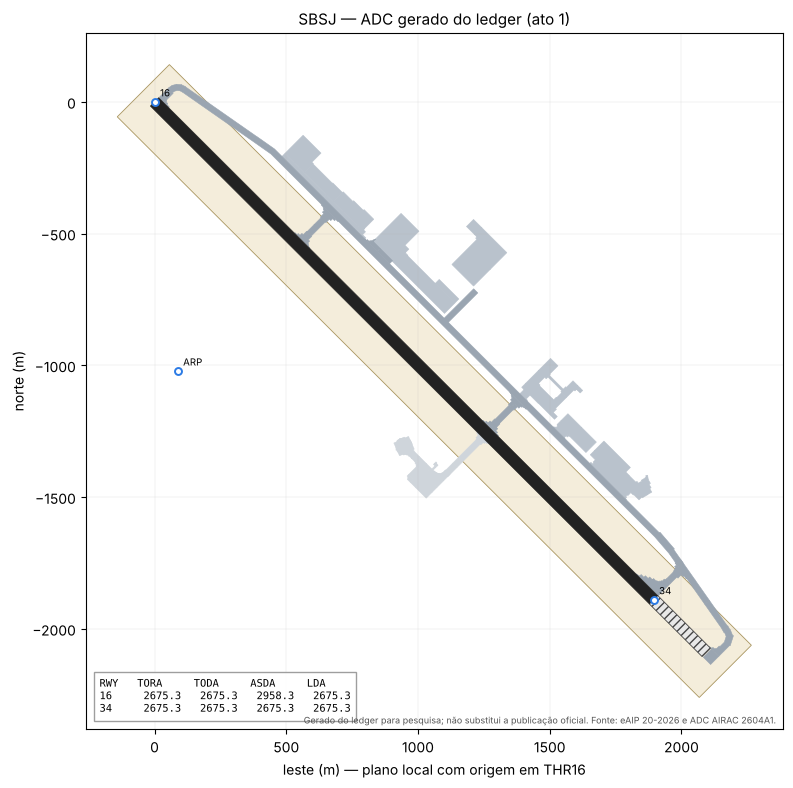

In [10]:
ADC1 = lente.projetar(conn, RUN)
fig, ax = plt.subplots(figsize=(9, 10))
figuras.adc(ADC1, "SBSJ — ADC gerado do ledger (ato 1)", "eAIP 20-2026 e ADC AIRAC 2604A1", ax)
fig.savefig(SAIDA / "ato1_adc.png", dpi=150, bbox_inches="tight")
plt.show()

### Verificação H2 — os derivados batem com o AIP

Comprimento e azimutes saem da geodésica entre as cabeceiras, sobre o GRS80 (método fixado no protocolo). O rumo magnético soma a variação de 22°W. As distâncias declaradas saem da regra. As tolerâncias são as do protocolo, derivadas da precisão de publicação do AD 2.12.

Por fim, H2.14 procura no ledger do modelo qualquer derivado armazenado. O prólogo, que guarda TORA e afins, está noutro run: é o sistema em modo forma, e é justamente o contraste.

In [11]:
L1 = derivacoes.comprimento(CORPO1, "RWY_16_34")
AZ1 = derivacoes.azimutes(CORPO1, "RWY_16_34")
reg.numerico("H2.01", L1)
reg.numerico("H2.02", AZ1["THR16"], angular=True)
reg.numerico("H2.03", AZ1["THR34"], angular=True)
reg.numerico("H2.04", derivacoes.rumo_magnetico(AZ1["THR16"], F.VARIACAO_LESTE), angular=True)
reg.numerico("H2.05", derivacoes.rumo_magnetico(AZ1["THR34"], F.VARIACAO_LESTE), angular=True)
DD = ADC1["distancias"]
for vid, (d, k) in {"H2.06": ("16", "TORA"), "H2.07": ("16", "TODA"), "H2.08": ("16", "ASDA"), "H2.09": ("16", "LDA"),
                    "H2.10": ("34", "TORA"), "H2.11": ("34", "TODA"), "H2.12": ("34", "ASDA"), "H2.13": ("34", "LDA")}.items():
    reg.numerico(vid, DD[d][k])
n = apoio.contar(conn, r'''SELECT count(*) FROM event_field f JOIN event e USING (event_id)
    WHERE e.run_id = %s AND (regexp_replace(f.path, '^.*\.', '') IN ('tora','toda','asda','lda','azimute','azimuth','rumo','bearing')
          OR (e.feature_type = 'runway' AND regexp_replace(f.path, '^.*\.', '') IN ('comprimento','length')))''', RUN)
reg.igual("H2.14", n, 0, "linhas de derivado no ledger do modelo")

✔ H2.01: observado 2675.3424 | predito 2675 ± 0.919 → PASSOU  (|Δ| = 0.3424)
✔ H2.02: observado 134.9346 | predito 134.9300 ± 0.014 → PASSOU  (|Δ| = 0.0046)
✔ H2.03: observado 314.9273 | predito 314.9200 ± 0.014 → PASSOU  (|Δ| = 0.0073)
✔ H2.04: observado 156.9346 | predito 157 ± 1.009 → PASSOU  (|Δ| = 0.0654)
✔ H2.05: observado 336.9273 | predito 337 ± 1.009 → PASSOU  (|Δ| = 0.0727)
✔ H2.06: observado 2675.3424 | predito 2675 ± 0.919 → PASSOU  (|Δ| = 0.3424)
✔ H2.07: observado 2675.3424 | predito 2675 ± 0.919 → PASSOU  (|Δ| = 0.3424)
✔ H2.08: observado 2958.3424 | predito 2958 ± 1.419 → PASSOU  (|Δ| = 0.3424)
✔ H2.09: observado 2675.3424 | predito 2675 ± 0.919 → PASSOU  (|Δ| = 0.3424)
✔ H2.10: observado 2675.3424 | predito 2675 ± 0.919 → PASSOU  (|Δ| = 0.3424)
✔ H2.11: observado 2675.3424 | predito 2675 ± 0.919 → PASSOU  (|Δ| = 0.3424)
✔ H2.12: observado 2675.3424 | predito 2675 ± 0.919 → PASSOU  (|Δ| = 0.3424)
✔ H2.13: observado 2675.3424 | predito 2675 ± 0.919 → PASSOU  (|Δ| = 0.342

True

### Verificação H1 — primitivos simples bastam para o ADC

Para cada unidade do desenho, a envoltória gerada pelo motor é comparada com o contorno da carta:

- **H1.01 (contenção):** o contorno está dentro da envoltória (guarda numérica de 1e-6 m);
- **H1.02 (desvio):** o percentil 95 da distância da borda da envoltória ao contorno fica dentro da tolerância (1,77 m, a precisão da carta);
- **H1.03 (parcimônia):** no máximo um primitivo por trecho do contorno;
- **H1.04 (coroas):** só se aplica se alguma unidade usar coroa;
- **H1.05 (posição, H1b):** pista e SWY geradas das premissas do AD 2.12 coincidem com o desenho, dentro de 1,95 m.

Para as unidades de pavimento, a envoltória vem do ledger, pela lente ADC. Para pista, SWY e faixa, H1a usa o ajuste ao desenho fora do ledger (o ledger guarda a versão das premissas, que é a de H1.05).

In [12]:
ENV = {e["adc"]["unidade_adc"]: (e["forma"], e["n_primitivos"]) for e in ADC1["elementos"] if e["adc"].get("unidade_adc")}
for uid, prims in FORA_DO_LEDGER.items():
    ENV[uid] = (motor.gerar({"primitivos": prims}, CORPO1)[0], len(prims))
LINHAS = []
for u in UNID:
    forma, n_prim = ENV[u["id"]]
    LINHAS.append({"unidade": u["id"], "rotulo": dig.rotulo(u)[1], "tol": CLASSE_TOL[u["classe"]],
                   "contencao": metricas.contencao(u["poligono"], forma),
                   "p95": metricas.desvio_p95(forma, u["poligono"]), "max": metricas.desvio_max(forma, u["poligono"]),
                   "prim": n_prim, "trechos": u["n_trechos"], "furos": len(u["furos"])})
display(Markdown("| unidade | rótulo | primitivos / trechos | contenção (m) | p95 (m) | máx (m) |\n|---|---|---|---|---|---|\n" +
                 "\n".join(f"| {l['unidade']} | {l['rotulo']} | {l['prim']} / {l['trechos']} | {l['contencao']:.1e} | "
                           f"{l['p95']:.2f} | {l['max']:.2f} |" for l in LINHAS)))
pior_c = max(LINHAS, key=lambda l: l["contencao"])
pior_d = max(LINHAS, key=lambda l: l["p95"] - l["tol"])
reg.limite("H1.01", pior_c["contencao"], reg.idx["H1.01"]["tolerancia_m"], f"pior unidade: {pior_c['unidade']}")
reg.limite("H1.02", pior_d["p95"], pior_d["tol"], f"pior unidade: {pior_d['unidade']} ({pior_d['rotulo']})")
violam = [l["unidade"] for l in LINHAS if l["prim"] > l["trechos"]]
reg.igual("H1.03", len(violam), 0, "unidades com mais primitivos que trechos" + (f": {violam}" if violam else ""))
reg.nao_executada("H1.04", "o ajuste desta versão usa só retângulos; nenhuma coroa foi gerada")
acima = [l for l in LINHAS if l["p95"] > l["tol"]]
if acima:
    display(Markdown("**Unidades acima da tolerância em H1.02:** " +
                     ", ".join(f"{l['unidade']} ({l['rotulo']}, p95 {l['p95']:.2f} m, {l['prim']}/{l['trechos']} primitivos)" for l in acima)))

| unidade | rótulo | primitivos / trechos | contenção (m) | p95 (m) | máx (m) |
|---|---|---|---|---|---|
| 786.0 | ligação | 1 / 6 | 5.2e-10 | 0.87 | 5.17 |
| 788.0 | STRIP | 1 / 4 | 1.2e-09 | 0.02 | 0.03 |
| 836.0 | APN 6 | 32 / 32 | 1.8e-09 | 3.44 | 8.13 |
| 837.0 | APN 7 | 15 / 25 | 8.0e-10 | 1.38 | 4.81 |
| 860.0 | APN 8 | 28 / 28 | 1.6e-09 | 3.71 | 8.90 |
| 872.0 | APN 4 | 9 / 9 | 6.7e-10 | 1.67 | 8.30 |
| 876.0 | APN 3 | 1 / 4 | 1.0e-09 | 1.26 | 1.50 |
| 885.0 | APN 1 | 11 / 11 | 1.1e-09 | 2.87 | 7.75 |
| 886.0 | APN 5 | 1 / 4 | 1.0e-09 | 0.25 | 0.28 |
| 887.0 | APN 4 | 6 / 7 | 1.2e-09 | 0.74 | 12.23 |
| 888.0 | APN 2 | 9 / 9 | 1.3e-09 | 2.04 | 9.73 |
| 889.0 | ligação | 11 / 12 | 1.2e-09 | 1.38 | 3.85 |
| 890.0 | TWY E | 13 / 16 | 2.9e-09 | 0.20 | 7.35 |
| 891.0 | TWY A | 10 / 10 | 1.1e-08 | 3.49 | 4.30 |
| 893.0 | TWY B | 22 / 22 | 1.6e-09 | 4.03 | 6.53 |
| 894.0 | TWY C | 22 / 22 | 1.2e-09 | 3.49 | 6.53 |
| 897.0 | TWY D | 15 / 15 | 2.7e-09 | 5.20 | 7.80 |
| 898.0 | TWY E | 21 / 21 | 1.7e-09 | 3.55 | 7.06 |
| 901.0 | pavimento sem designação (área de teste de motores e acessos) | 41 / 41 | 2.6e-09 | 1.55 | 5.17 |
| 902.0 | pavimento sem designação (área de teste de motores e acessos) | 13 / 13 | 1.1e-09 | 3.59 | 11.46 |
| 903.0 | pavimento sem designação (área de teste de motores e acessos) | 46 / 51 | 1.3e-09 | 1.60 | 3.95 |
| 904.0 | pavimento sem designação (área de teste de motores e acessos) | 8 / 8 | 8.7e-10 | 7.55 | 9.85 |
| 905.0 | pavimento sem designação (área de teste de motores e acessos) | 24 / 24 | 2.3e-09 | 2.59 | 3.77 |
| 906.0 | pavimento sem designação (área de teste de motores e acessos) | 8 / 15 | 1.3e-09 | 0.44 | 1.13 |
| 971.0 | TWY E | 1 / 4 | 9.6e-10 | 0.00 | 0.01 |
| 972.0 | RWY 16/34 | 1 / 4 | 7.2e-10 | 0.00 | 0.01 |
| 974.0 | SWY | 1 / 4 | 7.4e-10 | 0.00 | 0.00 |

✔ H1.01: observado 0.0000 | predito ≤ 1e-06 → PASSOU  (pior unidade: 891.0)
✘ H1.02: observado 7.5461 | predito ≤ 1.77 → FALHOU  (pior unidade: 904.0 (pavimento sem designação (área de teste de motores e acessos)))
✔ H1.03: observado 0 | predito 0 → PASSOU  (unidades com mais primitivos que trechos)
– H1.04: não executada (o ajuste desta versão usa só retângulos; nenhuma coroa foi gerada)


**Unidades acima da tolerância em H1.02:** 836.0 (APN 6, p95 3.44 m, 32/32 primitivos), 860.0 (APN 8, p95 3.71 m, 28/28 primitivos), 885.0 (APN 1, p95 2.87 m, 11/11 primitivos), 888.0 (APN 2, p95 2.04 m, 9/9 primitivos), 891.0 (TWY A, p95 3.49 m, 10/10 primitivos), 893.0 (TWY B, p95 4.03 m, 22/22 primitivos), 894.0 (TWY C, p95 3.49 m, 22/22 primitivos), 897.0 (TWY D, p95 5.20 m, 15/15 primitivos), 898.0 (TWY E, p95 3.55 m, 21/21 primitivos), 902.0 (pavimento sem designação (área de teste de motores e acessos), p95 3.59 m, 13/13 primitivos), 904.0 (pavimento sem designação (área de teste de motores e acessos), p95 7.55 m, 8/8 primitivos), 905.0 (pavimento sem designação (área de teste de motores e acessos), p95 2.59 m, 24/24 primitivos)

✘ H1.05: observado 63.0471 | predito ≤ 1.95 → FALHOU  (RWY 63.05 m; SWY 4.97 m)


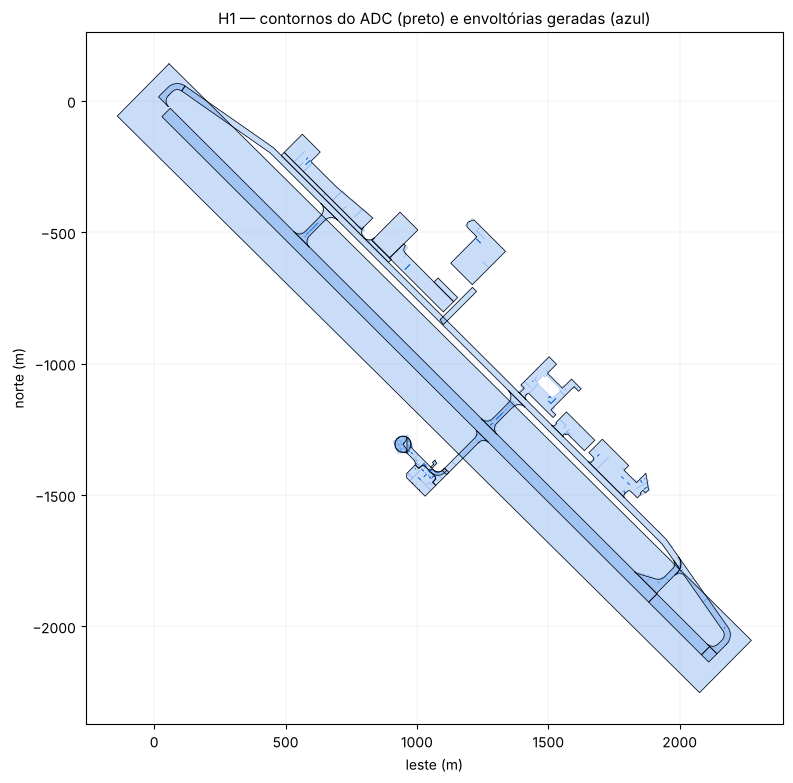

In [13]:
contorno = {u["id"]: u["poligono"] for u in UNID}
rwy = next(e["forma"] for e in ADC1["elementos"] if e["feature_id"] == "SBSJ-RWY")
swy = next(e["forma"] for e in ADC1["elementos"] if e["feature_id"] == "SBSJ-SWY")
h_rwy, h_swy = metricas.hausdorff(rwy, contorno["972.0"]), metricas.hausdorff(swy, contorno["974.0"])
reg.limite("H1.05", max(h_rwy, h_swy), reg.idx["H1.05"]["tolerancia_m"], f"RWY {h_rwy:.2f} m; SWY {h_swy:.2f} m")

fig, ax = plt.subplots(figsize=(9, 10))
figuras.h1(UNID, {k: v[0] for k, v in ENV.items()}, ax)
fig.savefig(SAIDA / "ato1_h1.png", dpi=150, bbox_inches="tight")
plt.show()

## Ato 2 — Obra (simulada)

O roteiro prevê aqui a instalação de uma barreira de contenção além da cabeceira 34, com o motor recalculando as distâncias declaradas pela regra da norma. Essa regra (como uma barreira reduz cada distância) ainda **não foi registrada no protocolo**. Escrever o evento e escolher a regra agora seria decidir a predição depois de começar a executar.

Por isso o ato fica de fora desta execução. Ele entra numa versão 0.5 do protocolo, com a regra registrada antes de rodar. O artefato já recusa o cálculo com uma barreira viva, em vez de adivinhar.

In [14]:
reg.nao_executada("R12", "a regra de distâncias declaradas com barreira ainda não está no protocolo (entra na v0.5)")

– R12: não executada (a regra de distâncias declaradas com barreira ainda não está no protocolo (entra na v0.5))


## Ato 3 — Restrição temporária

Em 1º de março de 2027 (simulado), o operador interdita um trecho da TWY E para uma obra no pavimento; em 15 de março, libera. No AIXM isso seria um TEMPDELTA, com a duração como categoria. Aqui são dois eventos comuns: um BASELINE da restrição, ligada à taxiway por `owner_ref`, e um VOID com motivo. A duração emerge da sequência.

In [15]:
T4, TA, T5 = (datetime(2027, 3, 1, tzinfo=UTC), datetime(2027, 3, 8, tzinfo=UTC), datetime(2027, 3, 15, tzinfo=UTC))
TWY_E = "SBSJ-PAV-890.0"
apoio.avancar_ate(conn, RUN, T4)
prims_e = ledger.reconstruct_state(conn, RUN, TWY_E, prefixo="geometria.")["geometria"]["primitivos"]
trecho = max(prims_e, key=lambda k: derivacoes.distancia_entre_seeds(CORPO1, prims_e[k]["inicio"], prims_e[k]["fim"]))
B4, _ = E(conn, RUN, "SBSJ-NOTAM-0001", "restriction", "BASELINE", owner_ref=TWY_E, asserted_by="operador SBSJ",
          reason="interdição temporária: obra no pavimento da TWY E (simulada)",
          corpo={"adc": {"designacao": "TWY E interditada", "tipo": "interdicao"},
                 "geometria": {"primitivos": {"trecho": prims_e[trecho]}}})
apoio.avancar_ate(conn, RUN, TA)
DD_TA = lente.projetar(conn, RUN, TA)["distancias"]          # o que valia em TA, calculado em TA
reg.nota("distâncias declaradas em TA, calculadas em TA", t=TA, distancias=DD_TA)
apoio.avancar_ate(conn, RUN, T5)
V5, _ = E(conn, RUN, "SBSJ-NOTAM-0001", "restriction", "VOID", owner_ref=TWY_E, asserted_by="operador SBSJ",
          reason="fim da obra (simulada)")
reg.nota("cabeça ao fim do ato 3", cabeca=ledger.cabeca(conn, RUN))

✔ R10.1: observado em 08/03/2027: sim | predito o ADC dentro de [t₄, t₅) mostra a interdição → PASSOU


✔ R10.2: observado 1 s antes de t₄: False; em t₅: False | predito o ADC fora de [t₄, t₅) não mostra → PASSOU
✔ R10.3: observado [('2027-03-01', 'BASELINE', 1), ('2027-03-15', 'VOID', 1)] | predito a segmentação do ciclo de vida devolve exatamente [t₄, t₅) → PASSOU


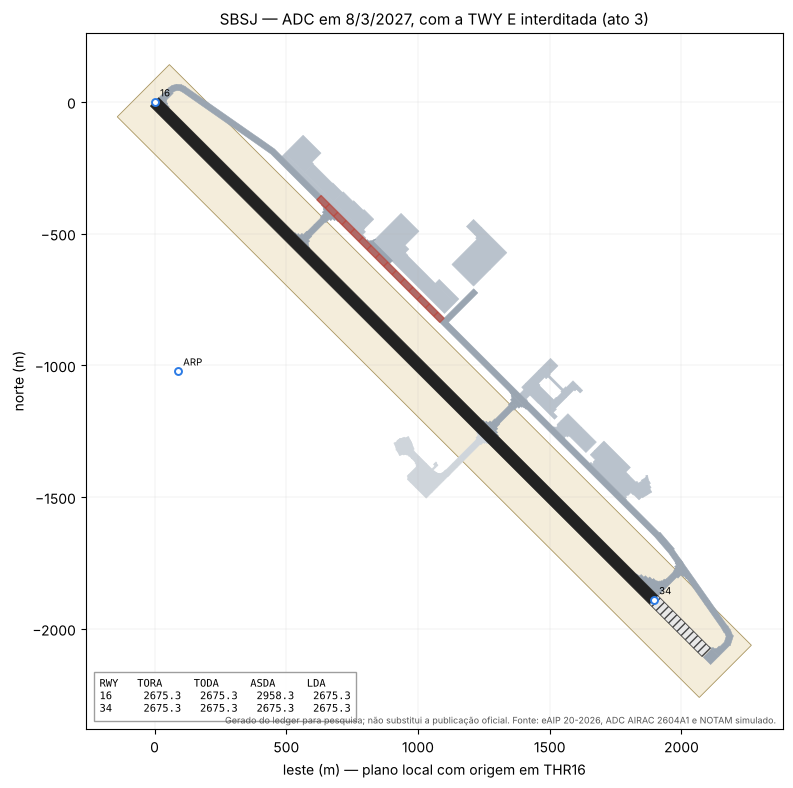

In [16]:
def tem_restricao(t):
    return any(e["tipo"] == "restriction" for e in lente.projetar(conn, RUN, t)["elementos"])

reg.roteiro("R10.1", tem_restricao(TA), "o ADC dentro de [t₄, t₅) mostra a interdição", observado=f"em {TA:%d/%m/%Y}: sim")
fora = [tem_restricao(apoio.um_segundo_antes(T4)), tem_restricao(T5)]
reg.roteiro("R10.2", not any(fora), "o ADC fora de [t₄, t₅) não mostra",
            observado=f"1 s antes de t₄: {fora[0]}; em t₅: {fora[1]}")
seg = ledger.ciclos(conn, RUN, "SBSJ-NOTAM-0001")
reg.roteiro("R10.3", seg == [(B4, "BASELINE", 1), (V5, "VOID", 1)] and relogio.instante(B4) == T4 and relogio.instante(V5) == T5,
            "a segmentação do ciclo de vida devolve exatamente [t₄, t₅)",
            observado=f"{[(relogio.instante(e).date().isoformat(), t, c) for e, t, c in seg]}")

fig, ax = plt.subplots(figsize=(9, 10))
figuras.adc(lente.projetar(conn, RUN, TA), "SBSJ — ADC em 8/3/2027, com a TWY E interditada (ato 3)",
            "eAIP 20-2026, ADC AIRAC 2604A1 e NOTAM simulado", ax)
fig.savefig(SAIDA / "ato3_adc.png", dpi=150, bbox_inches="tight")
plt.show()

## Ato 4 — Nova medição

Em 1º de junho de 2027 (simulado), a cabeceira 34 é remedida: 1,00 m para fora no prolongamento do eixo e 0,50 m para sudoeste, republicada a 0,01" (cenário fixado no protocolo antes da execução). Isso muda um ponto que **define** o eixo, então o que muda é o referencial: um corpo novo, com `ref_id` novo, e um único DELTA no `airport`. Nenhuma *seed* é tocada; o comprimento novo é derivado, não digitado.

O gabarito é outro algoritmo (Vincenty, em `protocolo/gabarito/`), em outro código, lendo as coordenadas direto do texto do AIP.

In [17]:
T6 = datetime(2027, 6, 1, tzinfo=UTC)
apoio.avancar_ate(conn, RUN, T6)
REF2 = referencial.publicar(conn, apoio.corpo_referencial(F.THR34_REMEDIDA, "remedição simulada (protocolo, ato 4)"))
CORPO2 = referencial.carregar(conn, REF2)
MARCO4 = apoio.maior_event_id(conn, RUN)
E6, _ = E(conn, RUN, "SBSJ", "airport", "DELTA", alteracoes={"referencial.ref_id": REF2},
          asserted_by="DECEA (simulado)", reason="remedição da THR 34 (simulada; cenário do protocolo, ato 4)")
FIM_ATO4 = apoio.maior_event_id(conn, RUN)
DEPOIS = apoio.depois_de(conn, RUN, MARCO4)
reg.nota("cabeça ao fim do ato 4", cabeca=ledger.cabeca(conn, RUN), fim_ato4=FIM_ATO4)

In [18]:
reg.igual("H2.15", [(f, t, et, paths) for _, f, t, et, paths in DEPOIS], [("SBSJ", "airport", "DELTA", ["referencial.ref_id"])])
COM_SEED = ("runway", "runway_direction", "protect_area", "taxiway", "apron", "pavement", "aerodrome_point")
reg.igual("H2.16", sum(1 for _, _, t, _, _ in DEPOIS if t in COM_SEED), 0, "eventos em features com seed no ato 4")
reg.igual("H2.17", sum(1 for *_, paths in DEPOIS for p in paths
                       if p.split(".")[-1] in ("comprimento", "length", "tora", "toda", "asda", "lda")), 0,
          "paths de comprimento ou distância declarada escritos no ato 4")

GAB = {1: {"THR16": (gab.aip(F.THR16["lat"]), gab.aip(F.THR16["lon"])), "THR34": (gab.aip(F.THR34["lat"]), gab.aip(F.THR34["lon"]))},
       2: {"THR16": (gab.aip(F.THR16["lat"]), gab.aip(F.THR16["lon"])),
           "THR34": (gab.aip(F.THR34_REMEDIDA["lat"]), gab.aip(F.THR34_REMEDIDA["lon"]))}}
pior, desloc = 0.0, []
for v in reg.protocolo["H2"]["ato4"]["vertices_verificados"]:
    ref, outro = v["referente"], ("THR34" if v["referente"] == "THR16" else "THR16")
    pts = {}
    for versao, corpo in ((1, CORPO1), (2, CORPO2)):
        m = Resolvedor(corpo).seed(s(ref, v["s"], v["o"]))[:2]
        g = gab.resolver(GAB[versao][ref], GAB[versao][outro], v["s"], v["o"])
        pior = max(pior, gab.inversa(m[0], m[1], g[0], g[1])[0])
        pts[versao] = m
    desloc.append((v["seed"], gab.inversa(*pts[1], *pts[2])[0]))
reg.limite("H2.18", pior, reg.idx["H2.18"]["tolerancia_m"], "maior distância motor × gabarito, com ref v1 e v2")
display(Markdown("| vértice | deslocamento com a remedição (m) |\n|---|---|\n" + "\n".join(f"| {n} | {d:.3f} |" for n, d in desloc)))

L2 = derivacoes.comprimento(CORPO2, "RWY_16_34"); AZ2 = derivacoes.azimutes(CORPO2, "RWY_16_34")
gL, gaz12, gaz21 = gab.inversa(*GAB[2]["THR16"], *GAB[2]["THR34"])
tol_az = 0.0005 / L2 * 180 / 3.141592653589793
dL, daz = abs(L2 - gL), max(abs(AZ2["THR16"] - gaz12), abs(AZ2["THR34"] - gaz21))
reg.composto("H2.19", f"ΔL = {dL:.1e} m; Δaz = {daz:.1e}°", f"ΔL ≤ 5e-4 m; Δaz ≤ {tol_az:.1e}°",
             dL <= 0.0005 and daz <= tol_az, f"comprimento novo {L2:.3f} m (antes {L1:.3f} m)")

✔ H2.15: observado [('SBSJ', 'airport', 'DELTA', ['referencial.ref_id'])] | predito [('SBSJ', 'airport', 'DELTA', ['referencial.ref_id'])] → PASSOU
✔ H2.16: observado 0 | predito 0 → PASSOU  (eventos em features com seed no ato 4)
✔ H2.17: observado 0 | predito 0 → PASSOU  (paths de comprimento ou distância declarada escritos no ato 4)
✔ H2.18: observado 0.0000 | predito ≤ 0.0005 → PASSOU  (maior distância motor × gabarito, com ref v1 e v2)


| vértice | deslocamento com a remedição (m) |
|---|---|
| RWY canto 16-dir | 0.004 |
| RWY canto 16-esq | 0.004 |
| RWY canto 34-dir | 0.969 |
| RWY canto 34-esq | 0.962 |
| SWY canto ext-dir | 0.992 |
| SWY canto ext-esq | 0.986 |

✔ H2.19: observado ΔL = 8.2e-08 m; Δaz = 9.5e-11° | predito ΔL ≤ 5e-4 m; Δaz ≤ 1.1e-05° → PASSOU  (comprimento novo 2676.195 m (antes 2675.342 m))


True

## Ato 5 — Auditoria

Agora, depois da remedição, um auditor escolhe um instante do passado: 8 de março de 2027, durante a interdição e antes da nova medição. Ele faz as três perguntas que a arquitetura existe para responder:

1. **Qual era o estado em t?** O ADC em t tem de sair do referencial vigente em t (v1), não do atual (v2).
2. **Quem afirmou, e sob qual regra?** O envelope da interdição tem de dizer quem e por quê; a norma vigente diz a regra.
3. **O número está certo?** As distâncias declaradas re-derivadas agora, das premissas retidas, têm de ser iguais às que valiam em t, calculadas em t (registradas no ato 3).

Sem barreira (ato 2 fora desta execução), a pergunta 2 se faz sobre a interdição do ato 3.

In [19]:
ADC_TA = lente.projetar(conn, RUN, TA)
ref_agora, _ = referencial.referencial_vigente(conn, RUN, relogio.limite(relogio.agora(conn, RUN)))
reg.roteiro("R8.1", ADC_TA["ref_id"] == REF1 and ref_agora == REF2,
            "o ADC em t usa o referencial vigente em t (v1), não o atual (v2)",
            observado=f"em t: {ADC_TA['ref_id'][:12]}… (v1); agora: {ref_agora[:12]}… (v2)")
env = ledger.envelope(conn, B4)
regra = ledger.reconstruct_state(conn, RUN, "SBSJ", TA, prefixo="norma.")["norma"]["regra_distancias"]
reg.roteiro("R8.2", env["asserted_by"] == "operador SBSJ" and bool(env["reason"]) and env["owner_ref"] == TWY_E,
            "o envelope diz quem afirmou a interdição, por quê e sobre o quê; a norma em t diz a regra",
            observado=f"{env['asserted_by']} · {env['reason']} · sobre {env['owner_ref']} · regra: {regra}")
reg.roteiro("R8.3", ADC_TA["distancias"] == DD_TA,
            "as distâncias re-derivadas das premissas retidas são as que valiam em t",
            observado=" · ".join(f"{d}: LDA {v['LDA']:.3f}" for d, v in sorted(ADC_TA["distancias"].items())))
display(Markdown("**O que mudou entre t e agora** (diff do ledger):\n\n| feature | campo | em t | agora |\n|---|---|---|---|\n" +
                 "\n".join(f"| {f} | `{p}` | {str(a)[:20]} | {str(b)[:20]} |" for f, p, a, b in ledger.diff(conn, RUN, TA, T6))))

✔ R8.1: observado em t: e66f79e71386… (v1); agora: fd72a389f5a4… (v2) | predito o ADC em t usa o referencial vigente em t (v1), não o atual (v2) → PASSOU
✔ R8.2: observado operador SBSJ · interdição temporária: obra no pavimento da TWY E (simulada) · sobre SBSJ-PAV-890.0 · regra: Anexo 14 Vol. I e RBAC 154: TORA = pista; TODA = TORA + CWY; ASDA = TORA + SWY; LDA = pista − deslocamento da cabeceira | predito o envelope diz quem afirmou a interdição, por quê e sobre o quê; a norma em t diz a regra → PASSOU
✔ R8.3: observado 16: LDA 2675.342 · 34: LDA 2675.342 | predito as distâncias re-derivadas das premissas retidas são as que valiam em t → PASSOU


**O que mudou entre t e agora** (diff do ledger):

| feature | campo | em t | agora |
|---|---|---|---|
| SBSJ | `referencial.ref_id` | e66f79e7138696cb7f39 | fd72a389f5a450ca5c1c |
| SBSJ-NOTAM-0001 | `adc.designacao` | TWY E interditada | <ausente> |
| SBSJ-NOTAM-0001 | `adc.tipo` | interdicao | <ausente> |
| SBSJ-NOTAM-0001 | `geometria.primitivos.trecho.fim.elemento` | RWY_16_34 | <ausente> |
| SBSJ-NOTAM-0001 | `geometria.primitivos.trecho.fim.o` | -183.72307924431416 | <ausente> |
| SBSJ-NOTAM-0001 | `geometria.primitivos.trecho.fim.referente` | THR16 | <ausente> |
| SBSJ-NOTAM-0001 | `geometria.primitivos.trecho.fim.s` | 1358.173783923822 | <ausente> |
| SBSJ-NOTAM-0001 | `geometria.primitivos.trecho.inicio.elemento` | RWY_16_34 | <ausente> |
| SBSJ-NOTAM-0001 | `geometria.primitivos.trecho.inicio.o` | -183.64039576118182 | <ausente> |
| SBSJ-NOTAM-0001 | `geometria.primitivos.trecho.inicio.referente` | THR16 | <ausente> |
| SBSJ-NOTAM-0001 | `geometria.primitivos.trecho.inicio.s` | 698.4933693664927 | <ausente> |
| SBSJ-NOTAM-0001 | `geometria.primitivos.trecho.largura` | 23.0095053138674 | <ausente> |
| SBSJ-NOTAM-0001 | `geometria.primitivos.trecho.tipo` | retangulo | <ausente> |

## Ato 6 — Adulteração

Por fim, alguém com acesso ao banco tenta reescrever a história, por fora de `append_event`. Cada ataque roda numa cópia do banco ao fim do ato 5, restaurada antes de cada um; o banco da execução não é tocado. Para cada ataque, o protocolo previu o resultado duas vezes: só com `verify_chain`, e com a âncora (o hash da cabeça registrado ao fim do ato 5, fora do banco).

As alterações que não deixam sucessor na cadeia (mexer na cabeça, truncar, reescrever até a cabeça) estão previstas como **não detectadas** sem âncora. Essa é a predição negativa de H3: sem âncora externa, quem controla o banco pode reescrever a cauda.

In [20]:
ANCORA = ledger.cabeca(conn, RUN)
reg.nota("âncora: cabeça ao fim do ato 5", cabeca=ANCORA)
K, K1, CAB = ataques.escolher_k(conn, RUN)
N_EVENTOS = apoio.contar(conn, "SELECT count(*) FROM event WHERE run_id = %s", RUN)
conn.close()

pred = {v["id"]: v for v in reg.protocolo["H3"]["verificacoes"]}
esperado_vc = {"detecta, devolve k": [K], "detecta, devolve k+1": [K1], "não detecta": []}
nome = lambda x: {K: "k", K1: "k+1"}.get(x, str(x))
for vid, descricao in ataques.ATAQUES.items():
    copia = f"{BANCO}_atk"
    ataques.copiar(apoio.ADMIN, BANCO, copia)
    c2 = apoio.reconectar(copia)
    ataques.atacar(c2, RUN, vid, K, CAB)
    vc, ca = ataques.detectar(c2, RUN, ANCORA)
    c2.close()
    ataques.apagar(apoio.ADMIN, copia)
    ev, ea = esperado_vc[pred[vid]["verify_chain"]], pred[vid]["com_ancora"] == "detecta"
    reg.composto(vid, f"verify_chain {[nome(x) for x in vc]}; âncora {'detecta' if ca else 'não detecta'}",
                 f"verify_chain {[nome(x) for x in ev]}; âncora {'detecta' if ea else 'não detecta'}",
                 vc == ev and ca == ea, descricao)

conn = apoio.reconectar(BANCO)
n_banco = apoio.contar(conn, "SELECT count(*) FROM event WHERE run_id = %s", RUN)
reg.composto("H3.10", f"{n_banco} eventos no banco; {reg.n_escritas[RUN]} escritas no registro; verify_chain {ledger.verify_chain(conn, RUN)}",
             "iguais; verify_chain []", n_banco == reg.n_escritas[RUN] and ledger.verify_chain(conn, RUN) == [])

✔ H3.01: observado verify_chain ['k']; âncora detecta | predito verify_chain ['k']; âncora detecta → PASSOU  (UPDATE em event_field.next do evento k, sem recalcular hash)


✔ H3.02: observado verify_chain ['k+1']; âncora detecta | predito verify_chain ['k+1']; âncora detecta → PASSOU  (UPDATE no corpo de k recalculando o hash de k)


✔ H3.03: observado verify_chain ['k']; âncora detecta | predito verify_chain ['k']; âncora detecta → PASSOU  (UPDATE em asserted_by de k, sem recalcular hash)


✔ H3.04: observado verify_chain ['k']; âncora detecta | predito verify_chain ['k']; âncora detecta → PASSOU  (DELETE de uma linha de event_field de k)


✔ H3.05: observado verify_chain ['k+1']; âncora detecta | predito verify_chain ['k+1']; âncora detecta → PASSOU  (DELETE do evento k)


...

✔ H3.07: observado verify_chain []; âncora detecta | predito verify_chain []; âncora detecta → PASSOU  (UPDATE no corpo da cabeça recalculando o hash da cabeça)


✔ H3.08: observado verify_chain []; âncora detecta | predito verify_chain []; âncora detecta → PASSOU  (DELETE da cabeça (truncamento))


✔ H3.09: observado verify_chain []; âncora detecta | predito verify_chain []; âncora detecta → PASSOU  (reescrita de k até a cabeça recalculando todos os hashes)


✔ H3.10: observado 34 eventos no banco; 34 escritas no registro; verify_chain [] | predito iguais; verify_chain [] → PASSOU


True

## Epílogo — Vinte anos depois

O ledger vai crescer: décadas de NOTAMs, inspeções, manutenção. H4 pergunta se ler o ADC continua barato. Um script separado (`experimento/escala.py`) monta ledgers sintéticos de 10³ a 10⁶ eventos, mantendo fixos os eventos relevantes ao ADC (os desta execução até o fim do ato 4) e acrescentando eventos irrelevantes de duas formas:

- **S1:** em outras features (incidentes);
- **S2:** nas mesmas features do ADC, numa camada que o contrato não lê (`manutencao`). É o teste do contrato como lente.

Para cada tamanho, mede a mediana de 21 projeções do ADC. Se o custo for dominado pela descida no índice, a inclinação log-log fica em 0,10 (o limite do protocolo); varredura sequencial daria 1,0.

A geração leva alguns minutos. Para pular, defina `TG_PULAR_ESCALA=1`.

In [21]:
ARQ_ESCALA = RAIZ / "resultados" / "escala.json"
if os.environ.get("TG_PULAR_ESCALA"):
    for vid in ("H4.01", "H4.02", "H4.03", "H4.04", "H4.05"):
        reg.nao_executada(vid, "escala pulada nesta execução (TG_PULAR_ESCALA)")
    ESC = None
else:
    r = subprocess.run([sys.executable, str(RAIZ / "experimento" / "escala.py"), BANCO, RUN, str(FIM_ATO4)],
                       capture_output=True, text=True)
    print(r.stdout[-3000:], r.stderr[-2000:])
    ESC = json.loads(ARQ_ESCALA.read_text())
    reg.nota("escala", arquivo=str(ARQ_ESCALA), K=ESC["K_relevantes"], hardware=ESC["hardware"])

S1 N=    1000: mediana    90.78 ms (geração 3 s) cache igual: True
S1 N=    3162: mediana    84.42 ms (geração 3 s) cache igual: True
S1 N=   10000: mediana    86.17 ms (geração 4 s) cache igual: True
S1 N=   31623: mediana    85.43 ms (geração 6 s) cache igual: True
S1 N=  100000: mediana    89.68 ms (geração 12 s) cache igual: True
S1 N=  316228: mediana   100.11 ms (geração 34 s) cache igual: True
S1 N= 1000000: mediana    86.29 ms (geração 101 s) cache igual: True
S1: inclinação 0.0071  IC95 [-0.015115284962202744, 0.025142171809837348]
S2 N=    1000: mediana    91.90 ms (geração 3 s) cache igual: True
S2 N=    3162: mediana    84.73 ms (geração 3 s) cache igual: True
S2 N=   10000: mediana   101.75 ms (geração 4 s) cache igual: True
S2 N=   31623: mediana   112.27 ms (geração 6 s) cache igual: True
S2 N=  100000: mediana   115.77 ms (geração 11 s) cache igual: True
S2 N=  316228: mediana   364.83 ms (geração 32 s) cache igual: True
 Traceback (most recent call last):
  File "/home

FileNotFoundError: [Errno 2] No such file or directory: '/home/claude/tg-protocolo/resultados/escala.json'

In [ ]:
if ESC:
    for vid, serie in (("H4.01", "S1"), ("H4.02", "S2")):
        sr = ESC["series"][serie]
        reg.limite(vid, sr["inclinacao"], reg.protocolo["H4"]["limite_da_inclinacao"]["valor"],
                   f"IC95 [{sr['ic95'][0]:.3f}, {sr['ic95'][1]:.3f}]")
    seq = [(srie, q) for srie, ps in ESC["planos"].items() for q, p in ps.items() if p["seq_scan"]]
    reg.igual("H4.03", seq, [], "consultas com Seq Scan em event/event_field no maior N")
    rel = sorted({r for ps in ESC["planos"].values() for p in ps.values() for r in p["relacoes"]})
    reg.composto("H4.04", rel, "⊆ ['event', 'event_field', 'referencial']",
                 set(rel) <= {"event", "event_field", "referencial"})
    ok = [all(ESC["series"][s]["cache_igual"]) for s in ("S1", "S2")]
    reg.composto("H4.05", f"S1 {ok[0]}, S2 {ok[1]}", "idênticos em todo N", all(ok))

    fig, ax = plt.subplots(figsize=(7, 4.5))
    for serie, cor in (("S1", "#2c7be5"), ("S2", "#c0392b")):
        sr = ESC["series"][serie]
        ax.loglog(ESC["tamanhos"], [m * 1000 for m in sr["medianas_s"]], "o-", color=cor,
                  label=f"{serie}: inclinação {sr['inclinacao']:.3f}")
    ax.set_xlabel("eventos no ledger (N)"); ax.set_ylabel("projeção do ADC, mediana (ms)")
    ax.set_title("H4 — custo de leitura do ADC conforme o ledger cresce")
    ax.grid(True, which="both", lw=0.3, alpha=0.5); ax.legend()
    fig.savefig(SAIDA / "epilogo_h4.png", dpi=150, bbox_inches="tight")
    plt.show()

## Fechamento

A tabela reúne os vereditos desta execução. Para cada falha, a pergunta que decide se ela refuta a tese é a do protocolo: **a correção exige violar um princípio da arquitetura** (premissa retida, derivado não armazenado, ledger só de escrita, transaction-time)? Se não, é falha de implementação: fica registrada aqui e no `execucoes.jsonl`, é corrigida, e o experimento roda de novo numa execução nova.

O R2 (as três perguntas do auditor contra o AIXM) é analítico e sai do capítulo 3, fora deste notebook.

In [ ]:
display(Markdown(reg.tabela()))
por = reg.resumo()
display(Markdown("| hipótese | passou | falhou | não executada |\n|---|---|---|---|\n" +
                 "\n".join(f"| {h} | {v['PASSOU']} | {v['FALHOU']} | {v['NÃO EXECUTADA']} |" for h, v in sorted(por.items()))))
falhas = [v for v in reg.vereditos if v["veredito"] == "FALHOU"]
print("falhas a classificar:", [v["id"] for v in falhas] or "nenhuma")
(SAIDA / "vereditos.json").write_text(json.dumps(reg.vereditos, indent=1, ensure_ascii=False, default=str))
print("vereditos em", SAIDA / "vereditos.json")